# Part 1: Extending the Date Range

### Ramith Vaid | NTU Singapore

The companion notebook (`portfolio_optimization.ipynb`) ran its full Markowitz/GARCH-informed comparison on 2014-01-01 to 2024-01-01, producing 9 non-overlapping 6-month rolling validation windows. Its own "Known Limitations" section flags this directly: *"Eight assets, one decade... a longer or higher-frequency dataset would give the rolling validation more windows and more statistical power, particularly since excluding even one window (the COVID crash) noticeably changes the picture, a sign the sample is still relatively small."*

This notebook extends `END` from `2024-01-01` through today, reusing the exact same, already-validated functions from `portfolio_utils.py` (factored out of the companion notebook, not rewritten). More calendar time means more non-overlapping 6-month windows -- a direct, mechanical fix for the small-sample limitation the project already identified in itself, plus a few years of genuinely fresh out-of-sample data (2024-2026) neither covariance approach could have been tuned to.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from portfolio_utils import (
    portfolio_variance, portfolio_return, min_variance_portfolio, max_sharpe_portfolio,
    build_efficient_frontier, build_garch_covariance, run_rolling_validation
)

print('Libraries loaded.')

Libraries loaded.


## 1. Data Collection (extended through today)

In [2]:
TICKERS = {
    'JPM':  'Financials',
    'AAPL': 'Technology',
    'XOM':  'Energy',
    'JNJ':  'Healthcare',
    'PG':   'Consumer Staples',
    'CAT':  'Industrials',
    'NEE':  'Utilities',
    'AMZN': 'Consumer Discretionary',
}
START = '2014-01-01'
END = None  # None = through the most recent available trading day

prices = {}
for ticker, sector in TICKERS.items():
    print(f'Downloading {ticker} ({sector})...')
    df = yf.download(ticker, start=START, end=END, progress=False)
    prices[ticker] = df['Close'].squeeze()

price_df = pd.DataFrame(prices).dropna()
print(f'\nCombined price data: {price_df.shape[0]} trading days, {price_df.shape[1]} assets '
      f'({price_df.index[0].date()} to {price_df.index[-1].date()})')
print(f'(Original companion-notebook run: 2516 trading days, 2014-01-02 to 2023-12-29)')


Combined price data: 3214 trading days, 8 assets (2014-01-02 to 2026-10-13)
(Original companion-notebook run: 2516 trading days, 2014-01-02 to 2023-12-29)


## 2. Full-sample Max Sharpe comparison (extended data)

Same method as the companion notebook: sample covariance vs. GARCH-informed covariance (GARCH volatilities x historical correlations), both capped at 35% per position.

In [3]:
log_returns = np.log(price_df / price_df.shift(1)).dropna()

ANNUALIZE = 252
mean_returns_sample = log_returns.mean() * ANNUALIZE
cov_sample = log_returns.cov() * ANNUALIZE
n_assets = len(TICKERS)

sharpe_weights_sample = max_sharpe_portfolio(mean_returns_sample, cov_sample, n_assets)
sharpe_vol_sample = np.sqrt(portfolio_variance(sharpe_weights_sample, cov_sample.values))

print('Fitting GARCH(1,1) per asset (8 assets, a few seconds each)...')
cov_garch, garch_vols_series = build_garch_covariance(log_returns, list(TICKERS.keys()))
sharpe_weights_garch = max_sharpe_portfolio(mean_returns_sample, cov_garch, n_assets)
sharpe_vol_garch = np.sqrt(portfolio_variance(sharpe_weights_garch, cov_garch.values))

print()
print('Max Sharpe Portfolio volatility, extended period vs. original companion-notebook run:')
print(f'  Sample covariance:  {sharpe_vol_sample*100:.2f}%   (original: 19.97%)')
print(f'  GARCH-informed:     {sharpe_vol_garch*100:.2f}%   (original: 14.20%)')

Fitting GARCH(1,1) per asset (8 assets, a few seconds each)...



Max Sharpe Portfolio volatility, extended period vs. original companion-notebook run:
  Sample covariance:  18.42%   (original: 19.97%)
  GARCH-informed:     14.48%   (original: 14.20%)


## 3. Rolling out-of-sample validation (extended data -> more windows)

In [4]:
windows, results_df = run_rolling_validation(log_returns, list(TICKERS.keys()), n_assets,
                                               annualize=ANNUALIZE, train_years=5, test_months=6)

print()
print(f'{len(windows)} windows total (original companion-notebook run: 9 windows).')
print(f'Average prediction error across all {len(windows)} windows:')
print(f'  Sample covariance: {results_df["sample_error"].mean()*100:.2f}% (std: {results_df["sample_error"].std()*100:.2f}%)')
print(f'  GARCH-informed:    {results_df["garch_error"].mean()*100:.2f}% (std: {results_df["garch_error"].std()*100:.2f}%)')

n_garch_better = (results_df['garch_error'] < results_df['sample_error']).sum()
print(f'\nGARCH-informed had lower error in {n_garch_better} of {len(windows)} windows.')

Running 15 rolling out-of-sample windows (5yr train, 6mo test each)...



  Window 1/15 (test starting 2019-01-07): sample_err=3.56%, garch_err=7.27%


  Window 2/15 (test starting 2019-07-09): sample_err=3.63%, garch_err=0.88%


  Window 3/15 (test starting 2020-01-07): sample_err=29.49%, garch_err=33.04%


  Window 4/15 (test starting 2020-07-08): sample_err=3.48%, garch_err=0.99%


...

  Window 11/15 (test starting 2024-01-09): sample_err=9.37%, garch_err=4.03%


  Window 12/15 (test starting 2024-07-11): sample_err=8.42%, garch_err=4.04%


  Window 13/15 (test starting 2025-01-10): sample_err=5.44%, garch_err=12.25%


  Window 14/15 (test starting 2025-07-15): sample_err=6.43%, garch_err=5.18%


  Window 15/15 (test starting 2026-01-13): sample_err=3.06%, garch_err=2.42%

15 windows total (original companion-notebook run: 9 windows).
Average prediction error across all 15 windows:
  Sample covariance: 7.36% (std: 6.66%)
  GARCH-informed:    6.23% (std: 8.29%)

GARCH-informed had lower error in 10 of 15 windows.


## 4. The COVID window, and checking for any new outliers

The companion notebook identified and excluded one outlier (the window whose test period runs into the Feb-Mar 2020 COVID crash) rather than averaging it away silently. With more windows now in the sample (extending through 2024-2026), this re-checks whether that's still the only outlier, or whether a new one shows up in the added, more recent period -- reported either way, not assumed.

In [5]:
outlier_window = results_df.loc[results_df['sample_error'].idxmax()]
print(f'Largest-error window: window {outlier_window["window"]}, test starting {outlier_window["test_start"]}')
print(f'  Sample error: {outlier_window["sample_error"]*100:.2f}%, GARCH error: {outlier_window["garch_error"]*100:.2f}%')
print()

sorted_errors = results_df.sort_values('sample_error', ascending=False)
print('Top 5 windows by sample-covariance error (to see whether the COVID window is still the standout, or whether a new period now rivals it):')
print(sorted_errors[['window', 'test_start', 'sample_error', 'garch_error']].head(5).to_string(index=False))
print()

results_excl = results_df.drop(outlier_window.name)
improvement = (results_excl['sample_error'].mean() - results_excl['garch_error'].mean()) / results_excl['sample_error'].mean() * 100
n_garch_better_excl = (results_excl['garch_error'] < results_excl['sample_error']).sum()

print(f'Excluding the single largest-error window ({len(results_excl)} of {len(results_df)} windows):')
print(f'  Sample covariance: {results_excl["sample_error"].mean()*100:.2f}% (original, 8-window version: 4.90%)')
print(f'  GARCH-informed:    {results_excl["garch_error"].mean()*100:.2f}% (original, 8-window version: 3.52%)')
print(f'  GARCH relative improvement: {improvement:.1f}% (original: 28.2%)')
print(f'  GARCH more accurate in {n_garch_better_excl} of {len(results_excl)} windows (original: 5 of 8)')

Largest-error window: window 3, test starting 2020-01-07
  Sample error: 29.49%, GARCH error: 33.04%

Top 5 windows by sample-covariance error (to see whether the COVID window is still the standout, or whether a new period now rivals it):
 window test_start  sample_error  garch_error
      3 2020-01-07      0.294924     0.330444
      7 2022-01-05      0.099843     0.121929
     11 2024-01-09      0.093739     0.040266
     10 2023-07-11      0.090482     0.043530
     12 2024-07-11      0.084219     0.040403

Excluding the single largest-error window (14 of 15 windows):
  Sample covariance: 5.78% (original, 8-window version: 4.90%)
  GARCH-informed:    4.32% (original, 8-window version: 3.52%)
  GARCH relative improvement: 25.4% (original: 28.2%)
  GARCH more accurate in 10 of 14 windows (original: 5 of 8)


## 5. Chart: per-window error, sample vs. GARCH-informed, extended period

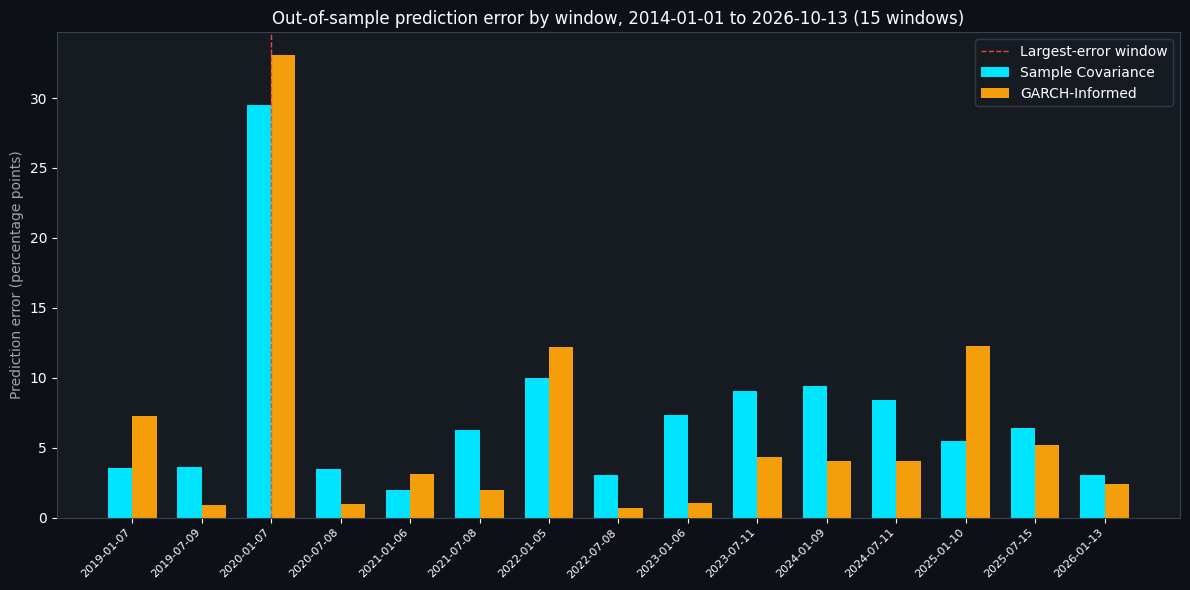

Saved chart_extended_rolling_windows.png


In [6]:
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#161b22')
ax.tick_params(colors='white')
for spine in ax.spines.values():
    spine.set_edgecolor('#374151')

x = np.arange(len(results_df))
width = 0.35
ax.bar(x - width/2, results_df['sample_error'] * 100, width, color='#00e5ff', label='Sample Covariance')
ax.bar(x + width/2, results_df['garch_error'] * 100, width, color='#f59e0b', label='GARCH-Informed')
ax.axvline(results_df.index.get_loc(outlier_window.name), color='#ef4444', linestyle='--', linewidth=1,
           label='Largest-error window')

ax.set_xticks(x)
ax.set_xticklabels([str(d) for d in results_df['test_start']], color='white', rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Prediction error (percentage points)', color='#9ca3af')
ax.set_title(f'Out-of-sample prediction error by window, {START} to {price_df.index[-1].date()} '
             f'({len(windows)} windows)', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white')

plt.tight_layout()
plt.savefig('chart_extended_rolling_windows.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_extended_rolling_windows.png')

## 6. Summary

In [7]:
print('=' * 70)
print('PART 1 SUMMARY: EXTENDED DATE RANGE')
print('=' * 70)
print(f'Date range: {START} to {price_df.index[-1].date()} '
      f'({price_df.shape[0]} trading days, vs. 2516 in the original 2014-2024 run)')
print(f'Rolling windows: {len(windows)} (vs. 9 originally)')
print()
print('Max Sharpe Portfolio volatility (full sample):')
print(f'  Sample covariance:  {sharpe_vol_sample*100:.2f}%  (original: 19.97%)')
print(f'  GARCH-informed:     {sharpe_vol_garch*100:.2f}%  (original: 14.20%)')
print()
print(f'Excluding the largest-error window ({len(results_excl)} windows):')
print(f'  Sample covariance: {results_excl["sample_error"].mean()*100:.2f}%  (original: 4.90%)')
print(f'  GARCH-informed:    {results_excl["garch_error"].mean()*100:.2f}%  (original: 3.52%)')
print(f'  GARCH relative improvement: {improvement:.1f}%  (original: 28.2%)')
print()
print('Files saved: chart_extended_rolling_windows.png')

PART 1 SUMMARY: EXTENDED DATE RANGE
Date range: 2014-01-01 to 2026-10-13 (3214 trading days, vs. 2516 in the original 2014-2024 run)
Rolling windows: 15 (vs. 9 originally)

Max Sharpe Portfolio volatility (full sample):
  Sample covariance:  18.42%  (original: 19.97%)
  GARCH-informed:     14.48%  (original: 14.20%)

Excluding the largest-error window (14 windows):
  Sample covariance: 5.78%  (original: 4.90%)
  GARCH-informed:    4.32%  (original: 3.52%)
  GARCH relative improvement: 25.4%  (original: 28.2%)

Files saved: chart_extended_rolling_windows.png
